In [1]:
# Cell 1: Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Cell 2: Load data
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [3]:
# Cell 3: Inspect missing values and target
target = "median_house_value"
if target not in df.columns:
    raise ValueError(f"Expected target column '{target}' was not found. Check the dataset URL.")

display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))
display(df[target].describe())
if "ocean_proximity" in df.columns:
    display(df["ocean_proximity"].value_counts())

,missing_count
total_bedrooms,207
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


,median_house_value
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


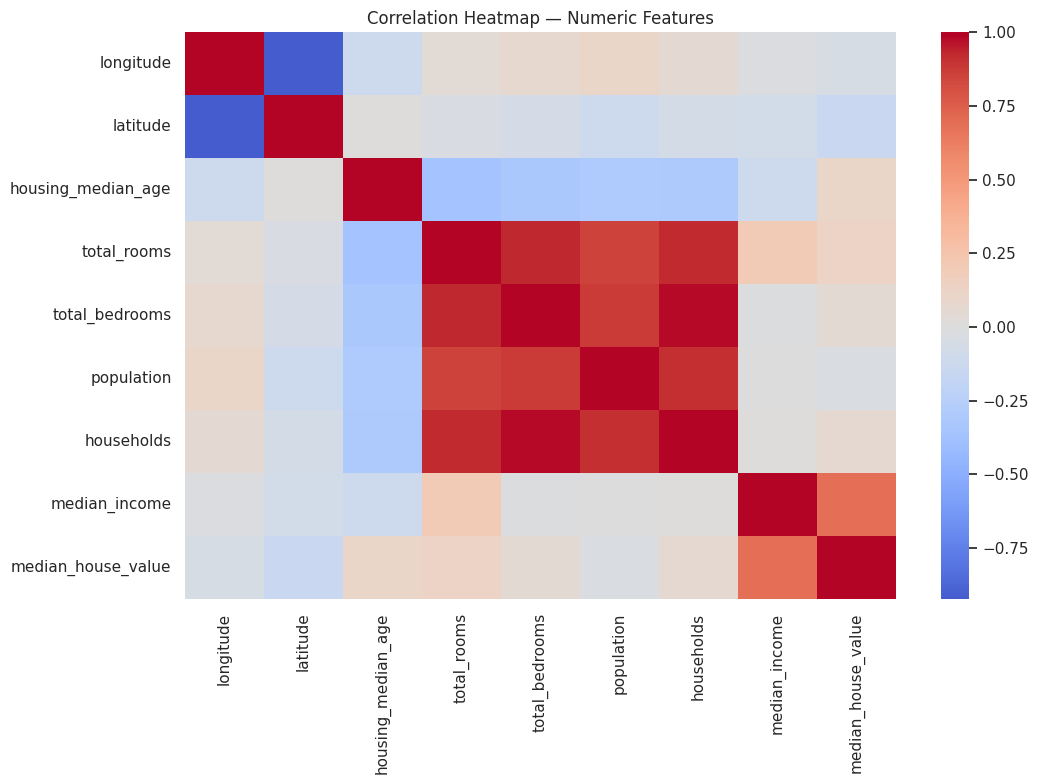

In [4]:
# Cell 4: Correlation heatmap for numeric columns
numeric_preview = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_preview.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.savefig("outputs/task2_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
# Cell 5: Train/test split
X = df.drop(columns=[target]).copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Train rows: 16512 | Test rows: 4128


In [6]:
# Cell 6: Preprocessing pipeline with numeric interaction features
# Interaction-only polynomial terms add pairwise interactions without squares.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


In [7]:
# Cell 7: Fit OLS baseline
ols_model = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", LinearRegression())
])
ols_model.fit(X_train, y_train)
ols_pred = ols_model.predict(X_test)
print("OLS model trained.")

OLS model trained.


In [8]:
# Cell 8: Tune Ridge and Lasso with cross-validation
# Use a small, transparent grid so this runs comfortably in Colab.
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
alpha_grid = {"regressor__alpha": [0.1, 1.0, 10.0, 100.0]}

ridge_search = GridSearchCV(
    Pipeline([("preprocess", preprocessor), ("regressor", Ridge())]),
    param_grid=alpha_grid, scoring="neg_root_mean_squared_error",
    cv=cv, n_jobs=-1, verbose=1
)
lasso_search = GridSearchCV(
    Pipeline([("preprocess", preprocessor), ("regressor", Lasso(max_iter=10000, tol=0.001))]),
    param_grid=alpha_grid, scoring="neg_root_mean_squared_error",
    cv=cv, n_jobs=-1, verbose=1
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)
print("Best Lasso parameters:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Ridge parameters: {'regressor__alpha': 0.1}
Best Ridge CV RMSE: 65641.6796391782
Best Lasso parameters: {'regressor__alpha': 100.0}
Best Lasso CV RMSE: 66201.56005940773


In [9]:
# Cell 9: Compare held-out test metrics
fitted_models = {
    "OLS / Linear Regression": ols_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}
predictions = {name: model.predict(X_test) for name, model in fitted_models.items()}

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

metrics_df = pd.DataFrame(rows).sort_values("RMSE")
display(metrics_df.round(3))
metrics_df.to_csv("outputs/task2_regression_metrics.csv", index=False)

,Model,RMSE,MAE,R2
0,OLS / Linear Regression,66788.296,47282.111,0.660
1,Ridge,67119.388,47577.646,0.656
2,Lasso,68299.595,48737.524,0.644


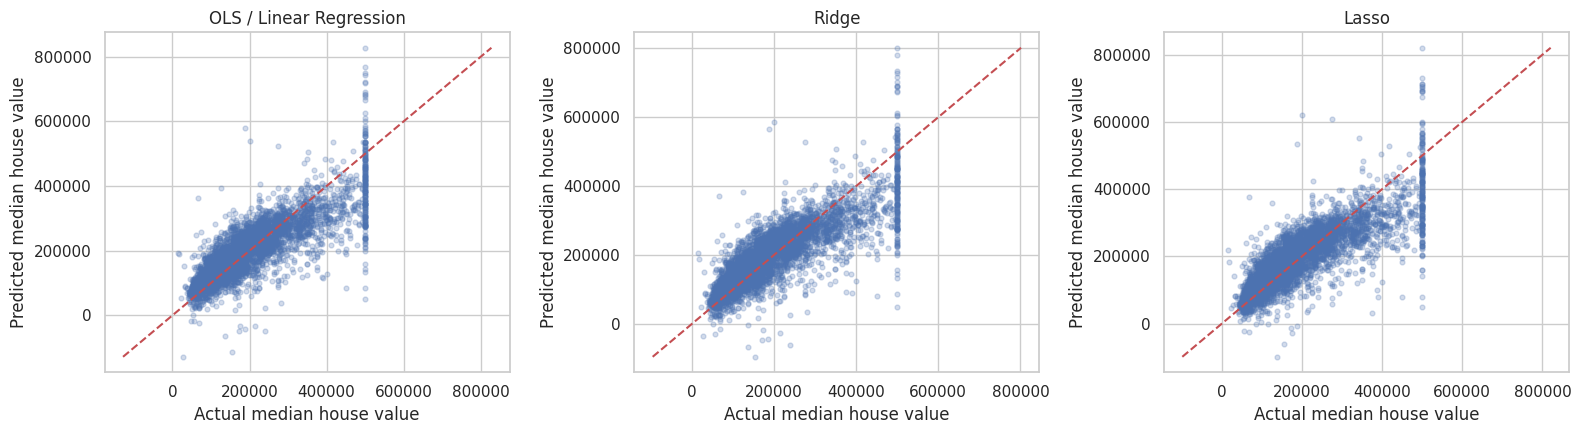

In [10]:
# Cell 10: Actual vs predicted plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.25, s=12)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], "r--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Actual median house value")
    ax.set_ylabel("Predicted median house value")
plt.tight_layout()
plt.savefig("outputs/task2_actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

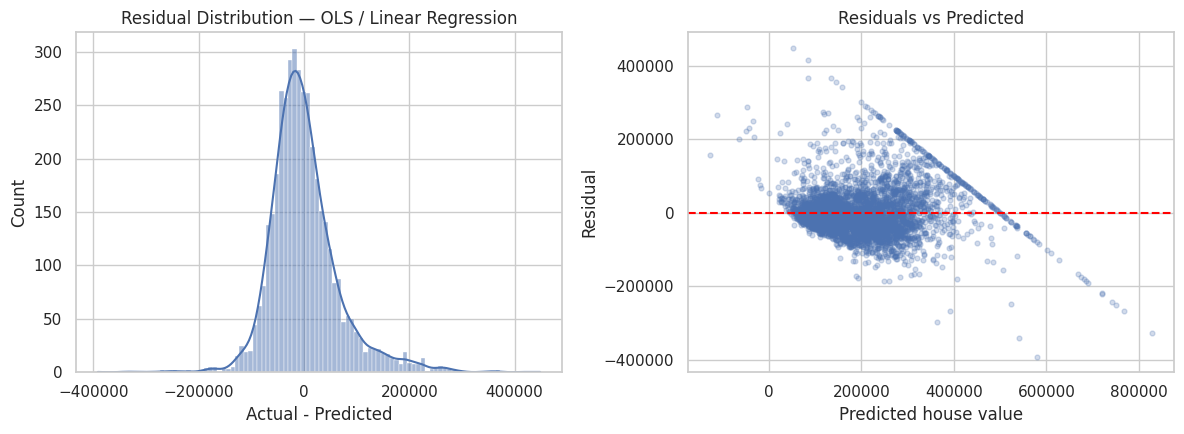

Best test RMSE model: OLS / Linear Regression


In [11]:
# Cell 11: Residual analysis for the best test-RMSE model
best_name = metrics_df.iloc[0]["Model"]
best_pred = predictions[best_name]
residuals = y_test.to_numpy() - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title(f"Residual Distribution — {best_name}")
axes[0].set_xlabel("Actual - Predicted")
axes[1].scatter(best_pred, residuals, alpha=0.25, s=12)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted house value")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.savefig("outputs/task2_residual_analysis.png", dpi=160, bbox_inches="tight")
plt.show()
print("Best test RMSE model:", best_name)